# code_210 · Match adaptation to the shift and retain a fallback

**Book:** section 39.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_39_GUIDE.md), [execution evidence](../CHAPTER_39_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_210).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Robustness contracts identify the source population, challenge mechanism, allowed adaptation information, physical checks and fallback. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8010;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8010


## Execute distinct adaptation objectives without merging their assumptions
 Source400 observations have x~Normal(0,1), y=x²+0.4x+noiseSD0.2. A target acquisition pool has200 inputs~Normal(1,1); its labels are revealed only after selecting40 indices by input alone. Fit a fixed linear response family (intercept+slope) deliberately misspecified for this nonlinear law. Compare source empirical least squares, clipped known simulator density-ratio weighting exp(x-0.5) capped at10, and true convex group-max regression over declared source groups x<0/x>=0. The latter solves an epigraph objective t+0.01||beta||² under both group mean-square-loss<=t constraints, with SLSQP and explicit success/slack checks. It is a small original convex group-robust experiment, not a neural benchmark or a general OOD guarantee. A separate unlabelled mean-alignment route subtracts target-pool mean minus source mean at inference. Here that intentionally treats a real covariate shift as though it were a hardware offset; the assumption can be wrong.


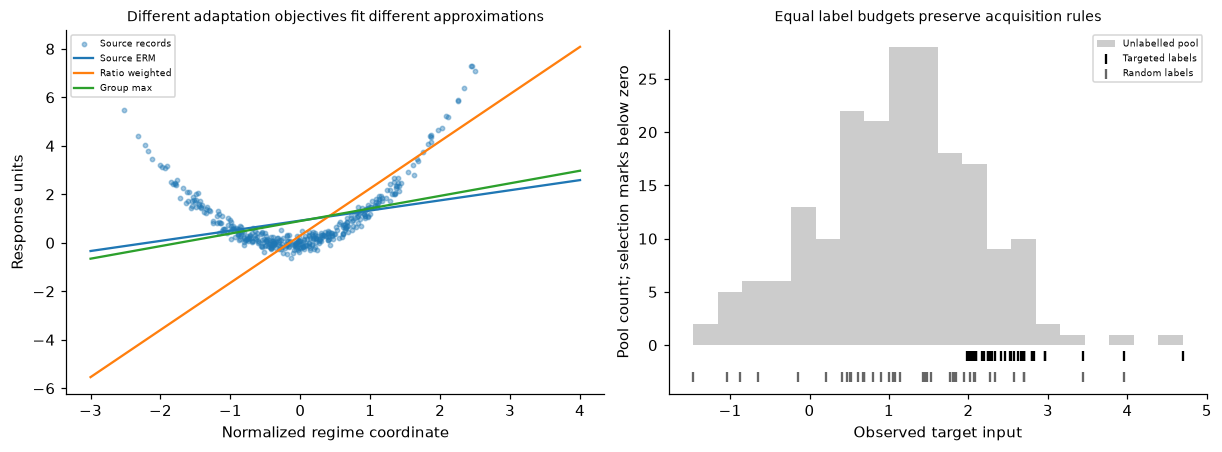

In [2]:
from scipy.optimize import minimize
sx=rng.normal(size=400);sy=sx**2+.4*sx+rng.normal(scale=.2,size=400);pool=rng.normal(1,1,200);design=np.c_[np.ones(400),sx]
def fit(x,y,weights=None):
    X=np.c_[np.ones(len(x)),x];w=np.ones(len(x)) if weights is None else weights;return np.linalg.solve(X.T@(w[:,None]*X)+.01*np.eye(2),X.T@(w*y))
erm=fit(sx,sy);weight=np.minimum(np.exp(sx-.5),10);weighted=fit(sx,sy,weight);groups=[sx<0,sx>=0];group_loss=lambda beta,g:float(np.mean((design[g]@beta-sy[g])**2));initial=np.r_[erm,max(group_loss(erm,g) for g in groups)+1];constraints=[{'type':'ineq','fun':lambda z,g=g:z[2]-group_loss(z[:2],g)} for g in groups];solution=minimize(lambda z:z[2]+.01*(z[:2]@z[:2]),initial,method='SLSQP',constraints=constraints,options={'maxiter':500,'ftol':1e-10});assert solution.success,solution.message;slacks=[float(solution.x[2]-group_loss(solution.x[:2],g)) for g in groups];assert min(slacks)>-1e-6;dro=solution.x[:2];mean_shift=float(pool.mean()-sx.mean());targeted=np.argsort(pool)[-40:];random_ids=rng.choice(200,40,replace=False);hidden_pool_outcomes=pool**2+.4*pool+rng.normal(scale=.2,size=200)
def adapted(ids):
    xnew=pool[ids];revealed=hidden_pool_outcomes[ids];return fit(np.r_[sx,xnew],np.r_[sy,revealed],np.r_[np.full(400,1/400),np.full(40,1/40)])
randomfit=adapted(random_ids);targetfit=adapted(targeted);betas={'Source ERM':erm,'Ratio weighted':weighted,'Group max':dro,'Mean alignment':erm,'Random 40 labels':randomfit,'Targeted 40 labels':targetfit};RESULTS.update(source_records=400,target_unlabelled_pool=200,target_label_budget_each=40,ratio_clipping=10,ratio_effective_sample_size=float(weight.sum()**2/(weight@weight)),known_density_ratio_is_simulator_oracle=True,group_max_optimizer_success=bool(solution.success),group_max_constraint_slacks=slacks,group_max_coefficients=dro.tolist(),unlabelled_alignment_shift=mean_shift,targeted_indices=targeted.tolist(),random_indices=random_ids.tolist(),adaptation_family='fixed linear intercept+slope',targeted_selection_uses_labels=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].scatter(sx,sy,s=8,alpha=.4,label='Source records');grid=np.linspace(-3,4,100)
for name in ['Source ERM','Ratio weighted','Group max']:axes[0].plot(grid,np.c_[np.ones(100),grid]@betas[name],label=name)
axes[0].set(xlabel='Normalized regime coordinate',ylabel='Response units',title='Different adaptation objectives fit different approximations');axes[0].legend(fontsize=6);axes[1].hist(pool,bins=20,color='.8',label='Unlabelled pool');axes[1].scatter(pool[targeted],np.full(40,-1),marker='|',color='black',label='Targeted labels');axes[1].scatter(pool[random_ids],np.full(40,-3),marker='|',color='.4',label='Random labels');axes[1].set(xlabel='Observed target input',ylabel='Pool count; selection marks below zero',title='Equal label budgets preserve acquisition rules');axes[1].legend(fontsize=6);plt.show()


## Freeze adaptation, then assess independent challenges and gate coverage
 Generate800 independent final familiar inputs and800 shifted inputs after all fits. Evaluate every frozen route on both cohorts; do not select the best final score. The mean-alignment route applies its acquired shift only to the target cohort. A source-defined acceptance envelope is its1st–99th input quantiles. Apply this fixed gate to the original source predictor and report accepted count/RMSE plus rejected count separately. A second final stress uses exactly the same shifted inputs with an added response jump of4 for x>1. No input-only gate changes, and covariate-ratio weighting does not identify this conditional change. Deferred cases remain unresolved obligations requiring an authorized alternative; they are not counted as correct predictions. This finite challenge is not a proof of safe deployment or field adaptation.


,Familiar,Covariate target,Changed response
Source ERM,1.589594,2.851772,5.314919
Ratio weighted,2.255750,1.625031,3.683197
Group max,1.587824,2.739477,5.187456
Mean alignment,1.589594,3.092172,5.635282
Random 40 labels,2.052849,1.701665,3.435994
Targeted 40 labels,2.517574,1.954459,2.648364


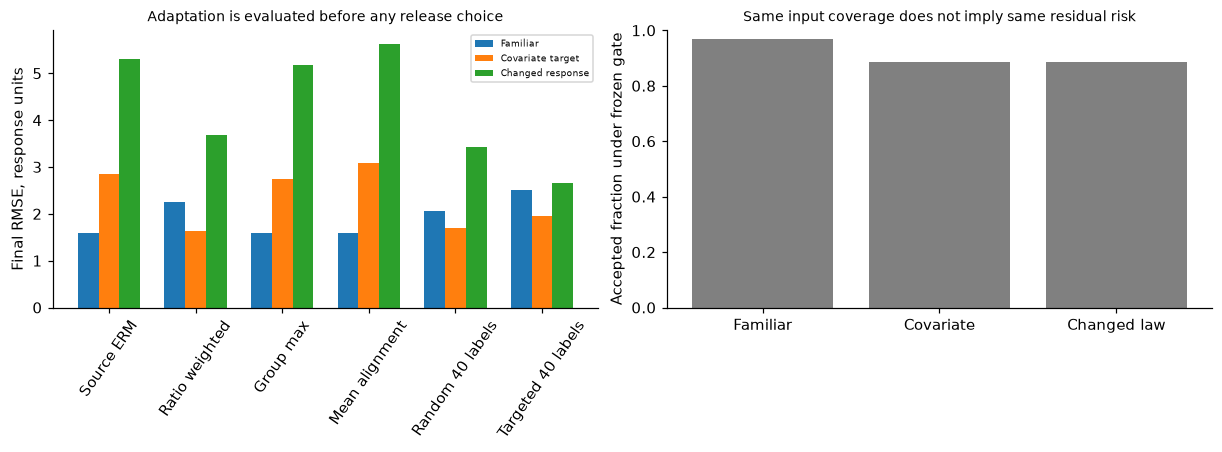

In [3]:
familiar=rng.normal(size=800);shifted=rng.normal(1,1,800);fy=familiar**2+.4*familiar+rng.normal(scale=.2,size=800);syfinal=shifted**2+.4*shifted+rng.normal(scale=.2,size=800);changed=syfinal+4*(shifted>1);cohorts={'Familiar':(familiar,fy),'Covariate target':(shifted,syfinal),'Changed response':(shifted,changed)};scores={}
for name,beta in betas.items():
    scores[name]={}
    for cohort,(x,y) in cohorts.items():
        values=x-mean_shift if name=='Mean alignment' and cohort!='Familiar' else x;p=np.c_[np.ones(len(x)),values]@beta;scores[name][cohort]=float(np.sqrt(np.mean((p-y)**2)))
envelope=np.quantile(sx,[.01,.99]);gates={}
for cohort,(x,y) in cohorts.items():
    accept=(x>=envelope[0])&(x<=envelope[1]);p=np.c_[np.ones(len(x)),x]@erm;gates[cohort]={'accepted':int(accept.sum()),'deferred':int((~accept).sum()),'coverage':float(accept.mean()),'accepted_RMSE':float(np.sqrt(np.mean((p[accept]-y[accept])**2)))}
assert gates['Covariate target']['coverage']==gates['Changed response']['coverage'];assert all(row['accepted']+row['deferred']==800 for row in gates.values());assert len(targeted)==len(random_ids)==40;RESULTS.update(final_RMSE=scores,source_acceptance_envelope=envelope.tolist(),source_predictor_gate_results=gates,final_scores_select_route=False,deferred_cases_counted_as_correct=False,conditional_change_keeps_same_inputs=True);display(pd.DataFrame(scores).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(len(scores))
for j,cohort in enumerate(cohorts):axes[0].bar(xx+(j-1)*.24,[scores[k][cohort] for k in scores],.24,label=cohort)
axes[0].set(xticks=xx,xticklabels=list(scores),ylabel='Final RMSE, response units',title='Adaptation is evaluated before any release choice');axes[0].tick_params(axis='x',rotation=55);axes[0].legend(fontsize=6);axes[1].bar(range(3),[gates[k]['coverage'] for k in gates],color='.5');axes[1].set(xticks=range(3),xticklabels=['Familiar','Covariate','Changed law'],ylabel='Accepted fraction under frozen gate',ylim=(0,1),title='Same input coverage does not imply same residual risk');plt.show()


In [4]:
summary={'example_id':'code_210','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual clipped density-ratio regression and effective sample size', 'actual convex group-max epigraph optimization with feasibility checks', 'unlabelled mean alignment and equal-budget random versus targeted target labels', 'independent challenge results with frozen source-envelope acceptance and explicit deferrals'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual clipped density-ratio regression and effective sample size", "actual convex group-max epigraph optimization with feasibility checks", "unlabelled mean alignment and equal-budget random versus targeted target labels", "independent challenge results with frozen source-envelope acceptance and explicit deferrals"], "elapsed_seconds": 0.21, "example_id": "code_210", "hardware": "Darwin arm64 CPU", "results": {"adaptation_family": "fixed linear intercept+slope", "conditional_change_keeps_same_inputs": true, "deferred_cases_counted_as_correct": false, "final_RMSE": {"Group max": {"Changed response": 5.187456065637795, "Covariate target": 2.739477373854633, "Familiar": 1.5878243122403308}, "Mean alignment": {"Changed response": 5.635282480552143, "Covariate target": 3.0921720858257573, "Familiar": 1.5895935250850495}, "Random 40 labels": {"Changed response": 3.435994427616863, "Covariate target": 1.701664828570896, "Familiar": 2.0528493